# Import a paired Run/Ch/Cy SPR export

Import **`paired_run.csv`**, inspect its metadata, and plot the measured
sensorgrams. This example uses a full-resolution selection committed with the repository;
it compares candidate fits and assesses their scientific limitations. No data download is required.

**Data origin:** [rstoolbox example03/spr_data.txt](https://github.com/lpdi-epfl/rstoolbox/blob/2bfc9be5ec6111603fb78700f201b80331ef0132/notebook/data/example03/spr_data.txt). Copyright (c) 2017 Jaume Bonet, MIT license.
This is a modified excerpt/conversion; the exact changes and pinned sources
are listed in [SOURCES.md](data/spr_exports/SOURCES.md).
The data and plotted sensorgrams retain their upstream license:
[full license notice](../test_files/spr_exports/rstoolbox-LICENSE).

In [1]:
from pathlib import Path
import sys
import warnings
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

%matplotlib inline

# Works from the repository root, notebooks/, or docs/notebooks/.
cwd = Path.cwd().resolve()
repo_root = next(
    path for path in (cwd, *cwd.parents)
    if (path / "src" / "pykingenie").is_dir()
    and (path / "test_files" / "spr_exports").is_dir()
)
for path in [repo_root / "src", repo_root / "notebooks"]:
    sys.path.insert(0, str(path))
from pykingenie import detect_file_format, SprTextExperiment, KineticsAnalyzer, plot_plate_info

plt.rcParams.update({"figure.dpi": 110, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
data_file = repo_root / "notebooks" / "data" / "spr_exports" / "paired_run.csv"
print("Input:", data_file.name)
fit_metadata = json.loads((data_file.parent / "fit_metadata.json").read_text())[data_file.stem]

Input: paired_run.csv


## File layout and representative selection

Paired `_X` time / `_Y` response columns. This teaching file contains the measured `conc=15`, `conc=30`, and `conc=60` series (cycles 14–16), with every finite source observation retained. There are 5,621 points per curve, rather than the 20-point weak-response curves in the separate parser-test fixture. No upstream fitted-curve columns are included in the input file.

The concentration labels have no verified unit and are not assumed to be µM. The source has 49 missing-response pairs in each selected curve. These 147 partial pairs are omitted from the teaching export; no finite response is discarded, and no value is interpolated or filled. Lines break across the resulting sampling gaps.

These exports do not establish injection-event timing. The boundaries below
are **provisional inferred events**, without independent experimental verification.
The sensorgram plot rejoins all partitions on the original time grid.
Verify actual injection timing and concentrations before fitting. Boundaries
are seconds, and association is `[association_start, association_end)`.

The expected missing-concentration warning is displayed below.
`sample_id="unassigned"` is a grouping placeholder, not a recovered sample identity.

The kinetic section makes the provisional event boundaries explicit and tests
±1 s timing changes. They are inferred from transitions, not recovered event logs.
No molar concentration is assigned to this experiment.

In [2]:
association_start = fit_metadata["association_start"]
association_end = fit_metadata["association_end"]

print("Detected layout:", detect_file_format(data_file))

experiment = SprTextExperiment("paired_run")
with warnings.catch_warnings(record=True) as messages:
    warnings.simplefilter("always", UserWarning)
    experiment.read_file(
        data_file,
        association_start=association_start,
        association_end=association_end,
        decimal='.',
        time_unit="s",
        sample_id="unassigned",
    )
for message in messages:
    print(message.message)
print(f"Imported {experiment.no_sensors} measured curves; {experiment.no_steps} API phases.")
assert experiment.traces_loaded and experiment.no_sensors == 3

Detected layout: spr_text
Some analyte concentrations are unavailable or have no unit. Provide concentrations or edit ligand_conc_df before fitting.
Imported 3 measured curves; 3 API phases.


## Available curve information

Each measured curve becomes a sensor in the experiment object. Its complete
original label remains in `sensor_names`. The following table extracts only
the header/row-label fields present in this specific example file.

In [3]:
curve_ids = [f"Curve {i + 1}" for i in range(experiment.no_sensors)]
labels = pd.Series(experiment.sensor_names, name="Exported label")
header_info = labels.str.extract('Run\\s+(?P<Run>\\d+);\\s*Ch\\s+(?P<Channel>\\d+);\\s*Cy\\s+(?P<Cycle>\\d+);.*conc=(?P<Concentration_label>.+)$')
header_info.insert(0, "Curve", curve_ids)
display(header_info)
display(labels.to_frame())
plot_labels = header_info["Concentration_label"].tolist()

,Curve,Run,Channel,Cycle,Concentration_label
0,Curve 1,1,1,14,15
1,Curve 2,1,1,15,30
2,Curve 3,1,1,16,60


,Exported label
0,Run 1; Ch 1; Cy 14; RefSub; 1kx8_d02; conc=15
1,Run 1; Ch 1; Cy 15; RefSub; 1kx8_d02; conc=30
2,Run 1; Ch 1; Cy 16; RefSub; 1kx8_d02; conc=60


## Concentration metadata

`NaN` means a molar concentration is unavailable, not zero concentration.
Before fitting, supply your verified values through `concentrations` and
`concentration_unit` at import, or update `ligand_conc_df`. A list follows the
measured-curve order; a mapping can use full exported curve labels as keys.

In [4]:
concentration_info = experiment.ligand_conc_df.copy()
concentration_info.insert(0, "Curve", curve_ids)
display(concentration_info[["Curve", "Concentration_micromolar", "SampleID"]])
assert concentration_info["Concentration_micromolar"].isna().all()

,Curve,Concentration_micromolar,SampleID
0,Curve 1,NaN,unassigned
1,Curve 2,NaN,unassigned
2,Curve 3,NaN,unassigned


## Plate information, when available

Run, channel and cycle numbers identify acquisitions, not sample-plate wells. No row/column coordinates are present.

The conditional cell below uses `plot_plate_info` only when the experiment
actually contains the required plate metadata. It prints a message for this
file rather than assigning artificial well positions.

In [5]:
analyzer = KineticsAnalyzer()
analyzer.add_experiment(experiment, experiment.name)
plate_fields = (
    "sample_row", "sample_column", "sample_type", "sample_id", "sample_conc_labeled"
)
have_plate_info = all(
    getattr(experiment, field) is not None
    and len(getattr(experiment, field)) > 0
    for field in plate_fields
)
if have_plate_info:
    display(pd.DataFrame({field: getattr(experiment, field) for field in plate_fields}))
    plot_plate_info(analyzer, experiment.name).show()
else:
    print("No plate-well coordinates are available in this export; no plate plot is created.")

No plate-well coordinates are available in this export; no plate plot is created.


## Imported sensorgrams

Every finite source observation in the selected curves is plotted at its original
time. No resampling, smoothing or baseline subtraction is applied. Lines break
across gaps larger than three median sampling intervals. Legend entries use the
original concentration labels or cycle/flow-cell identifiers shown above.

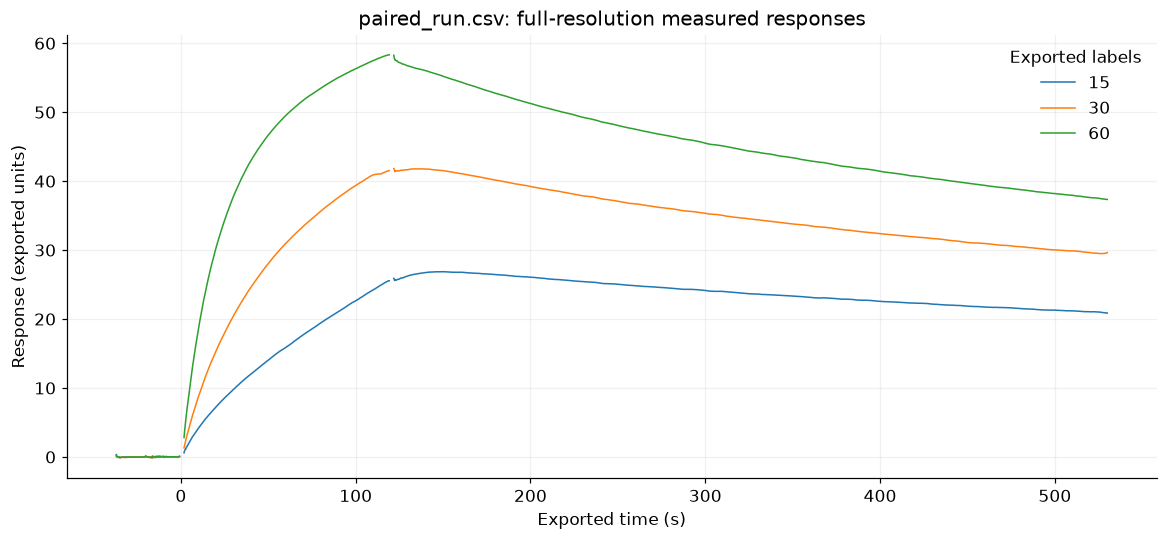

In [6]:
fig, ax = plt.subplots(figsize=(10.5, 4.8), constrained_layout=True)
axes = [ax]
for i, label in enumerate(plot_labels):
    time = np.concatenate(experiment.xs[i])
    response = np.concatenate(experiment.ys[i])
    breaks = np.flatnonzero(np.diff(time) > 3 * np.median(np.diff(time))) + 1
    segments = np.split(np.arange(len(time)), breaks)
    for axis in axes:
        for j, indices in enumerate(segments):
            axis.plot(time[indices], response[indices], color=f"C{i}", linewidth=1,
                      label=label if j == 0 else None)
for axis in axes:
    axis.set(xlabel="Exported time (s)", ylabel="Response (exported units)")
    axis.legend(frameon=False, title="Exported labels")
    axis.grid(alpha=0.18)
ax.set_title("paired_run.csv: full-resolution measured responses")
plt.show()

## Check the retained points and import partitions

The original times remain in `xs`; `ys` contains the corresponding measured
responses. Duke phase times come from the companion metadata. The rstoolbox and
binning phase boundaries remain provisional. For binning, post-event data include
later protocol steps; the fit below uses only an explicitly limited early episode.

In [7]:
imported_points = pd.DataFrame([
    {
        "Curve": curve_ids[i],
        "Baseline points": len(experiment.xs[i][0]),
        "Association points": len(experiment.xs[i][1]),
        "Dissociation points": len(experiment.xs[i][2]),
        "Total points": sum(len(step) for step in experiment.xs[i]),
        "First exported time (s)": np.concatenate(experiment.xs[i])[0],
        "Last exported time (s)": np.concatenate(experiment.xs[i])[-1],
    }
    for i in range(experiment.no_sensors)
])
display(imported_points)
display(experiment.df_steps[["Name", "Type", "Start"]])

,Curve,Baseline points,Association points,Dissociation points,Total points,First exported time (s),Last exported time (s)
0,Curve 1,362,1176,4083,5621,-36.900002,530.0
1,Curve 2,362,1176,4083,5621,-36.900002,530.0
2,Curve 3,362,1176,4083,5621,-36.900002,530.0


,Name,Type,Start
0,Baseline,BASELINE,-36.900002
1,Association,ASSOC,0.000000
2,Dissociation,DISASSOC,120.000000


All finite source observations in the teaching selections remain available in
the import. The fitting masks below leave transition regions out of the objective;
they do not remove observations from the experiment or shift the physical clock.
Source selection, omitted missing pairs and data licenses:
[SOURCES.md](data/spr_exports/SOURCES.md).

## Fitting setup and physical assumptions

The concentration scale is the exported label scale **15, 30, 60**. Its
physical unit is unverified. Affinities and association rates are labelled in
**concentration-label units**, never µM or M. Event times 0 and 120 s are inferred.
The fit calls `align_association` to subtract the mean of the last 10
pre-association observations and assumes an initially empty surface. Compare one-site, lumped transport, two independent ligand populations,
and two-state induced-fit models, each with shared and per-curve Rmax.

In [8]:
display(pd.DataFrame({
    "Curve": curve_ids,
    "Fit concentration": fit_metadata["concentrations"] or ["unavailable"] * len(curve_ids),
    "Concentration unit": fit_metadata["concentration_unit"] or "not assigned",
}))
display(pd.Series({key: fit_metadata[key] for key in (
    "association_start", "association_end", "fit_end", "timing_verified",
    "molar_concentrations_verified", "regenerated", "bulk_shift", "initial_occupancy", "protocol"
)}).to_frame("Fit metadata"))
for source in fit_metadata["sources"]:
    print("Metadata/source:", source)

,Curve,Fit concentration,Concentration unit
0,Curve 1,15,exported concentration-label units (unverified)
1,Curve 2,30,exported concentration-label units (unverified)
2,Curve 3,60,exported concentration-label units (unverified)


,Fit metadata
association_start,0
association_end,120
fit_end,530
timing_verified,False
molar_concentrations_verified,False
regenerated,None
bulk_shift,False
initial_occupancy,zero after pre-injection background subtraction
protocol,Unverified run metadata; compare shapes in the...


Metadata/source: https://github.com/lpdi-epfl/rstoolbox/blob/2bfc9be5ec6111603fb78700f201b80331ef0132/notebook/data/example03/spr_data.txt


## Align association, then compare candidate models

The notebook driver uses **pyKinGenie's forward binding functions** and SciPy
bounded least squares, with eight reproducible starting points (seed 2918).
It retains the true injection clock and propagates state at the physical switch,
including when transition points are masked. See [spr_fitting.py](spr_fitting.py).

Exclude 3 s around injection transitions; fit at most one original observation
per second, without averaging. Carterra's slower records retain their native
spacing. This reduces oversampling but does **not** establish independent errors.
Before fitting, make a copy and call
`fit_experiment.align_association(inplace=True, npoints=10)`. This subtracts
the mean of the last 10 baseline observations from every phase of each curve.
It changes response zeroes, not timestamps. The table below verifies that the
aligned pre-association mean is zero. The original `experiment` and raw plot
above remain unchanged. No additional median-baseline subtraction is applied
to the aligned fitting copy.

The removed offsets are recorded in `fit_metadata["association_alignment"]`.
For Carterra, the physical initial bound signal is reconstructed from the
aligned baseline plus its removed offset. Model predictions subtract the same
offset, so fitting uses aligned responses while preserving occupied initial
states. Fixed offset/initial estimates remain uncertain; the sensitivity
analysis does not make them exact.

Every candidate uses the same selected observations. BIC is
`n*log(RSS/n) + k*log(n)`; `k` includes rates, fractions, per-curve capacities and
RI terms. Lower BIC ranks these candidates **conditional on the noise/model
assumptions**. Reduced χ² here is `RSS/(n-k)` with unit variance; it is not a
calibrated chi-square goodness-of-fit test, and a value below 1 is not validation.

In [9]:
from copy import deepcopy
from spr_fitting import run_analysis, parameter_table, plot_fit, trust_assessment

# Preserve the imported experiment and explicitly align every fitting curve.
fit_experiment = deepcopy(experiment)
association_step = int(experiment.df_steps.index[experiment.df_steps["Type"] == "ASSOC"][0])
alignment_points = 10
alignment_offsets = {
    name: float(np.mean(experiment.ys[i][association_step - 1][-alignment_points:]))
    for i, name in enumerate(experiment.sensor_names)
}
fit_experiment.align_association(inplace=True, npoints=alignment_points)
fit_metadata = deepcopy(fit_metadata)
fit_metadata["association_alignment"] = {
    "method": "align_association",
    "npoints": alignment_points,
    "offsets_by_sensor": alignment_offsets,
}
aligned_baseline_means = [
    float(np.mean(fit_experiment.ys[i][association_step - 1][-alignment_points:]))
    for i in range(fit_experiment.no_sensors)
]
assert np.allclose(aligned_baseline_means, 0, atol=1e-10)
display(pd.DataFrame({
    "Curve": curve_ids,
    "Subtracted pre-association mean": list(alignment_offsets.values()),
    "Aligned pre-association mean": aligned_baseline_means,
}))

analysis = run_analysis(fit_experiment, fit_metadata, n_starts=8, sensitivity=True)
display(analysis["comparison"].style.format(precision=4, na_rep="not identified"))
if not analysis["failures"].empty:
    display(analysis["failures"])

# Optional: export the numerical audit report with
# from spr_fitting import save_report
# save_report(analysis, "my_fit_report.json", data_file.stem)

,Curve,Subtracted pre-association mean,Aligned pre-association mean
0,Curve 1,0.02586,5.551115e-18
1,Curve 2,-0.05980,4.163336e-18
2,Curve 3,0.04124,6.938894e-18


,Model,Rmax,Parameters,Points,Reduced χ² (unit variance),RMSE,BIC,ΔBIC,Jacobian condition,Max |parameter correlation|,Near bounds,Converged starts
0,heterogeneous,local,8,1569,0.4178,0.6447,-1318.6377,0.0000,2790.8526,1.0000,,8/8
1,mass_transport,local,6,1569,0.7846,0.8841,-342.4841,976.1535,19.5964,0.9479,,8/8
2,one_site,local,5,1569,0.9424,0.9692,-61.2770,1257.3606,11.3849,0.9197,,8/8
3,induced_fit,local,7,1569,0.9349,0.9647,-61.2029,1257.4348,115.7489,0.9906,k_rev,8/8
4,heterogeneous,shared,6,1569,1.2831,1.1306,429.2395,1747.8772,256596.3191,1.0000,"fraction, Rmax_1",8/8
5,induced_fit,shared,5,1569,1.7677,1.3274,925.5788,2244.2164,92.9408,0.9654,,8/8
6,one_site,shared,3,1569,2.9227,1.7079,1701.8207,3020.4584,8.3846,0.8944,,8/8
7,mass_transport,shared,4,1569,2.9245,1.7079,1709.1790,3027.8167,16.6575,0.8974,Ktr,8/8


## Lowest-BIC fit and residuals

Thin solid lines are the association-aligned data; dashed lines are the selected fitted
curves. Grey bands indicate excluded transition regions. The residual panel is
essential: an excellent-looking overlay can still have long systematic errors.
For binning, this figure shows only the fitted early episode.

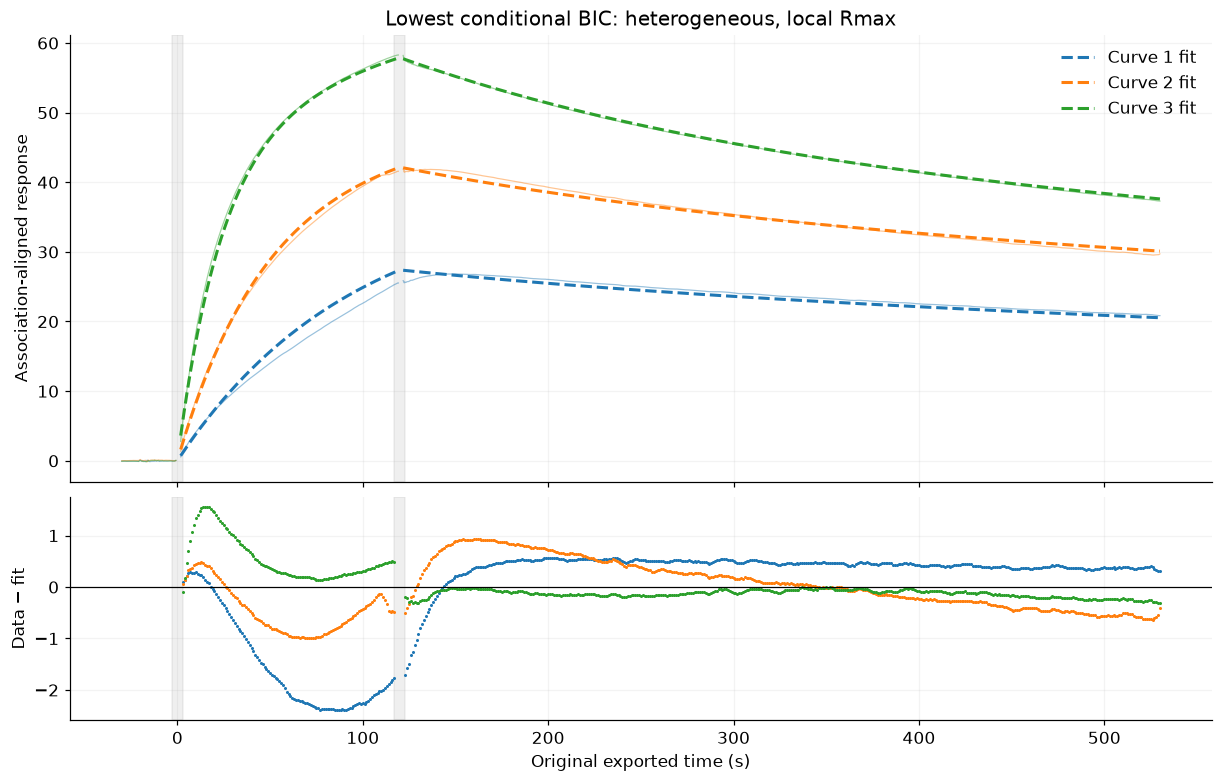

In [10]:
fig_fit = plot_fit(analysis)
plt.show()

## Parameters and identifiability

Intervals below are **nominal local iid least-squares intervals**, conditional
on the chosen model, fixed baseline/initial signal, event times and input
concentrations. Correlated residuals or model mismatch make them overconfident.
They are not bootstrap/profile intervals or proof of a molecular mechanism.
Derived `k_on = k_off/Kd` entries are point estimates; no interval is claimed.
Extreme intervals, near-unit correlations and near-bound parameters indicate
that individual parameters should not be interpreted.

In [11]:
display(parameter_table(analysis).style.format({
    "Estimate": "{:.4g}", "Conditional 95% lower": "{:.4g}",
    "Conditional 95% upper": "{:.4g}",
}, na_rep="not profiled/identified"))
display(analysis["best"]["correlation"].style.format(precision=3, na_rep="not identified"))
display(analysis["best"]["residuals"].style.format(precision=4))

,Parameter,Unit,Estimate,Conditional 95% lower,Conditional 95% upper
0,Kd1,label unit,0.625,0.5019,0.7783
1,k_off1,1/s,0.0004509,0.0003729,0.0005452
2,Kd2,label unit,136.2,20.15,920
3,k_off2,1/s,0.005187,0.004488,0.005994
4,fraction,dimensionless,0.349,0.03216,0.6658
5,Rmax_1,exported response unit,97.66,37.26,256
6,Rmax_2,exported response unit,110.9,42.29,290.6
7,Rmax_3,exported response unit,125.5,47.81,329.4
8,k_on1,1/(label unit·s),0.0007214,not profiled/identified,not profiled/identified
9,k_on2,1/(label unit·s),3.809e-05,not profiled/identified,not profiled/identified


,Kd1,k_off1,Kd2,k_off2,fraction,Rmax_1,Rmax_2,Rmax_3
Kd1,1.000,0.997,0.947,0.949,-0.928,0.936,0.935,0.935
k_off1,0.997,1.000,0.959,0.941,-0.943,0.950,0.949,0.949
Kd2,0.947,0.959,1.000,0.953,-0.998,0.999,0.999,0.999
k_off2,0.949,0.941,0.953,1.000,-0.935,0.942,0.941,0.941
fraction,-0.928,-0.943,-0.998,-0.935,1.000,-1.000,-1.000,-1.000
Rmax_1,0.936,0.950,0.999,0.942,-1.000,1.000,1.000,1.000
Rmax_2,0.935,0.949,0.999,0.941,-1.000,1.000,1.000,1.000
Rmax_3,0.935,0.949,0.999,0.941,-1.000,1.000,1.000,1.000


,Curve,Points,RMSE,Lag-1 residual correlation,Baseline noise estimate,RMSE / baseline noise
0,Run 1; Ch 1; Cy 14; RefSub; 1kx8_d02; conc=15,523,0.9249,0.9996,0.0165,56.1943
1,Run 1; Ch 1; Cy 15; RefSub; 1kx8_d02; conc=30,523,0.5149,0.9988,0.0134,38.3694
2,Run 1; Ch 1; Cy 16; RefSub; 1kx8_d02; conc=60,523,0.3554,0.9966,0.0104,34.2456


## Sensitivity of the selected model

Refit the selected family after changing trimming, sampling interval,
dissociation-window length and event times. Parameter entries are **ratios to
the primary fit**: 1 means unchanged, 1.5 means 50% higher. These runs use different
observations, so their BIC values would not be directly comparable. A fitting
failure is reported, not treated as a biological finding.

In [12]:
display(analysis["sensitivity"].style.format(precision=4, na_rep="—"))

,Perturbation,RMSE,Kd1,k_off1,Kd2,k_off2,fraction
0,trim 6 s,0.6399,0.9938,0.9905,0.7587,0.9854,1.1455
1,trim 10 s,0.6318,1.0009,0.9881,0.6075,0.9757,1.2676
2,5 s observation spacing,0.6448,0.9684,0.9755,0.8841,0.9838,1.0475
3,half dissociation window,0.7073,0.6128,0.6024,80.8369,1.3671,0.0287
4,event times -1 s,0.6561,1.0450,0.9855,0.9579,0.9948,1.0152
5,event times +1 s,0.6588,0.9406,0.9984,0.9266,0.9964,1.0383


## Decision: can the final fit be trusted?

The decision below separates a descriptive curve fit from validated intrinsic
kinetic constants. It uses the residuals, parameter coupling, available metadata
and sensitivity checks, not BIC or optimizer convergence alone.

In [13]:
from IPython.display import Markdown

assessment = trust_assessment("paired_run", analysis)
display(Markdown("**" + assessment["Verdict"] + "**"))
for reason in assessment["Reasons"]:
    display(Markdown("- " + reason))

**No validated kinetic result; lowest BIC is a comparative fit only.**

- The concentration unit and injection events are not independently verified.

- All tested models retain strongly structured residuals; the best residual lag-1 correlations exceed 0.99.

- The two-population fit has almost perfectly correlated parameters and a broad second-affinity interval.

- Halving the dissociation window changes the second affinity by roughly two orders of magnitude and drives the population fraction to its bound.

- No affinity in µM or M can be reported. Quantitative rates remain conditional on inferred timing and a misspecified response model.

Detailed methods, source metadata and cross-notebook conclusions:
[SPR_FITTING.md](SPR_FITTING.md).

Scientific context: [Cytiva kinetics/affinity application guide](https://cdn.cytivalifesciences.com/api/public/content/digi-33041-pdf)
and [Schuck & Zhao, mass transport and surface heterogeneity](https://pmc.ncbi.nlm.nih.gov/articles/PMC4134667/).
Statistical improvement alone does not identify a physical mechanism; experimental
controls and identifiability must support a kinetic interpretation.